## The Data

At this link, you will find a dataset containing information about heart disease patients: https://www.dropbox.com/scl/fi/0vrpdnq5asmeulc4gd50y/ha_1.csv?rlkey=ciisalceotl77ffqhqe3kujzv&dl=1

A description of the original dataset can be found here: https://archive.ics.uci.edu/dataset/45/heart+disease (However, this dataset has been cleaned and reduced, and the people have been given fictious names.)

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

## 1. Logistic Regression

Fit a Logistic Regression using only `age` and `chol` (cholesterol) as predictors.

For a 55 year old, how high would their cholesterol need to be for the doctors to predict heart disease is present?

How high for the doctors to estimate a 90% chance that heart disease is present?

Load the data

In [19]:
df = pd.read_csv("https://www.dropbox.com/scl/fi/0vrpdnq5asmeulc4gd50y/ha_1.csv?rlkey=ciisalceotl77ffqhqe3kujzv&dl=1")

In [20]:
X = df[["age", "chol"]]
y = (df["diagnosis"] == "Disease").astype(int)

logit = LogisticRegression(C=np.inf, max_iter=10000)
logit.fit(X, y)

b0 = logit.intercept_[0]
b_age, b_chol = logit.coef_[0]
print("Intercept:", round(b0, 4))
print("Age coefficient:", round(b_age, 4))
print("Chol coefficient:", round(b_chol, 4))



# (a) 
chol_50 = (0 - b0 - b_age * 55) / b_chol

print(f"55-year-old: predicted to have disease when chol is below {chol_50:.1f}")

# (b) 
chol_90 = (np.log(0.9 / 0.1) - b0 - b_age * 55) / b_chol
print(f"55-year-old: 90% chance of disease would need chol of about {chol_90:.1f} (impossible, since chol cannot be negative)")

Intercept: 3.2407
Age coefficient: -0.0469
Chol coefficient: -0.0018
55-year-old: predicted to have disease when chol is below 367.9
55-year-old: 90% chance of disease would need chol of about -852.3 (impossible, since chol cannot be negative)


so for a 55-year-old, the doctors would predict heart disease when their cholesterol is below about 368. This may seem strange, but in this data the cholesterol number has a negative effect, so higher cholesterol actually makes the model a little less likely to predict heart disease. For the doctors to estimate a 90% chance of heart disease, the cholesterol would need to be about -852. That is impossible because cholesterol can never be negative, so no cholesterol level would give a 55-year-old a 90% chance of heart disease.

## 2. Linear Discriminant Analysis

Fit an LDA model using only `age` and `chol` (cholesterol)  as predictors.

For a 55 year old, how high would their cholesterol need to be for the doctors to predict heart disease is present?

In [21]:
lda = LinearDiscriminantAnalysis()
lda.fit(X, y)

l0 = lda.intercept_[0]
l_age, l_chol = lda.coef_[0]

chol_lda = (0 - l0 - l_age * 55) / l_chol
print(f"LDA: 55-year-old predicted to have disease when chol is below {chol_lda:.1f}")

LDA: 55-year-old predicted to have disease when chol is below 366.8


LDA gives almost the same result as logistic regression. For a 55-year-old, it predicts heart disease when cholesterol is **below about 367**.

## 3. Support Vector Classifier

Fit an SVC model using only `age` and `chol` as predictors.  Don't forget to tune the regularization parameter.

For a 55 year old, how high would their cholesterol need to be for the doctors to predict heart disease is present?

In [22]:

svc_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("svc", SVC(kernel="linear"))
])

params = {"svc__C": [0.001, 0.01, 0.1, 1, 10, 100]}
grid = GridSearchCV(svc_pipe, params, cv=5, scoring="accuracy")
grid.fit(X, y)

print("Best C:", grid.best_params_["svc__C"])
print("Cross-validated accuracy:", round(grid.best_score_, 3))

svc = grid.best_estimator_

scaler = svc.named_steps["scale"]
w = svc.named_steps["svc"].coef_[0] / scaler.scale_
s0 = svc.named_steps["svc"].intercept_[0] - np.sum(w * scaler.mean_)
s_age, s_chol = w

chol_svc = (0 - s0 - s_age * 55) / s_chol
print(f"SVC: 55-year-old predicted to have disease when chol is below {chol_svc:.1f}")

Best C: 10
Cross-validated accuracy: 0.598
SVC: 55-year-old predicted to have disease when chol is below 312.7


After trying several values of `C` with 5-fold cross-validation, the best was **C = 10** (about 60% accuracy). For a 55-year-old, the SVC predicts heart disease when cholesterol is **below about 313**.

## 4. Comparing Decision Boundaries

Make a scatterplot of `age` and `chol`, coloring the points by their true disease outcome.  Add a line to the plot representing the **linear separator** (aka **decision boundary**) for each of the three models above.

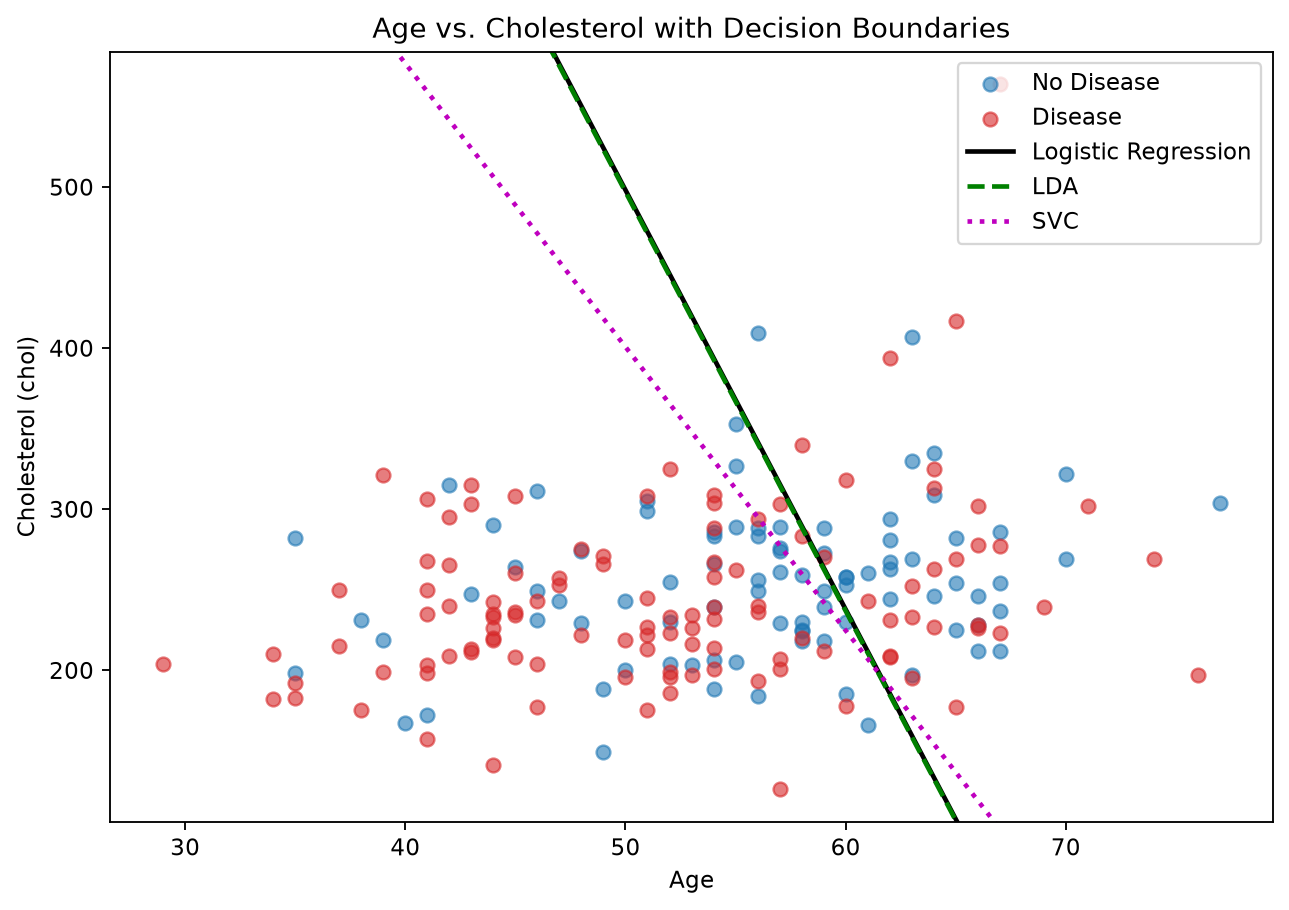

In [23]:

plt.figure(figsize=(9, 6))
for label, color in [("No Disease", "tab:blue"), ("Disease", "tab:red")]:
    part = df[df["diagnosis"] == label]
    plt.scatter(part["age"], part["chol"], c=color, label=label, alpha=0.6)

ages = np.linspace(df["age"].min(), df["age"].max(), 100)
plt.plot(ages, -(b0 + b_age * ages) / b_chol, "k-",  lw=2, label="Logistic Regression")
plt.plot(ages, -(l0 + l_age * ages) / l_chol, "g--", lw=2, label="LDA")
plt.plot(ages, -(s0 + s_age * ages) / s_chol, "m:",  lw=2, label="SVC")

plt.ylim(df["chol"].min() - 20, df["chol"].max() + 20)
plt.xlabel("Age")
plt.ylabel("Cholesterol (chol)")
plt.title("Age vs. Cholesterol with Decision Boundaries")
plt.legend()
plt.show()

What the plot shows: All three lines slope downward, and points below a line are predicted "Disease". The logistic regression and LDA lines are almost on top of each other. The SVC line is a bit lower. The red and blue points are very mixed together, so no straight line separates them well. This tells us age and cholesterol alone are weak predictors of heart disease in this data.